In [1]:

import itertools
import math
from functools import lru_cache
import matplotlib.pyplot as plt

import numpy as np
import sys


In [2]:
# Expected completion time of the lower-bound (benchmark) method:
#   N partitions, k worker nodes.
#   Each round, every live worker works on a different unfinished partition.
#   When fewer partitions are left than live workers, workers are spread as
#   evenly as possible over the remaining partitions (round robin).
# Failure model: each working worker fails with probability P in a round,
# independently, except that the last live worker never fails.
# Times are in rounds; multiply by T for time.

def round_robin_groups(r, a):
    """Group sizes when a live workers are spread over min(r, a) partitions by round robin."""
    x = min(r, a)
    return [a // x + (1 if i < a % x else 0) for i in range(x)]

# print(round_robin_groups(3, 10))
# [4, 3, 3], 4 workers to first parition, etc.

# print(round_robin_groups(5, 2))
# [1, 1], 1 worker to first parition, etc


def failure_sets(a, P):
    """Every possible set of failed workers (out of a live workers) with its probability.
    Workers fail independently; if all a would fail, one (chosen at random) survives."""
    outcomes = {}
    for failed in itertools.product([False, True], repeat=a):
        f = sum(failed)
        p = P ** f * (1 - P) ** (a - f)
        if f == a:                                  # everyone would fail: one survives
            for survivor in range(a):
                s = tuple(i != survivor for i in range(a))
                outcomes[s] = outcomes.get(s, 0) + p / a
        else:
            outcomes[failed] = outcomes.get(failed, 0) + p
    return outcomes.items()

#print(failure_sets(3, 0.2))
# F/F/F --> 0.512 = 0.8^3, etc
# cannot return 
# dict_items([((False, False, False), 0.5120000000000001), ((False, False, True), 0.12800000000000003), ((False, True, False), 0.12800000000000003), ((False, True, True), 0.03466666666666667), ((True, False, False), 0.12800000000000003), ((True, False, True), 0.03466666666666667), ((True, True, False), 0.03466666666666667)])




# ---------- 1. Exact: recursion over (partitions left r, live workers a) ----------

def A_expected_rounds_recursive(N, k, P):
    # E(0, a) = 0, all partitions finished
    # E(r, 1) = r, last worker cant fail
    # two cases: 1. r >= a, every worker unique parition
    # 2. r < a, at end where multiple workers to 1 partition
    @lru_cache(maxsize=None)
    # E(r, a) = 1 + Σ (probability of outcome × E(next state))
    # 1 is the current round
    def E(r, a):
        if r == 0:
            return 0.0                              # nothing left
        if a == 1:
            return float(r)                         # last worker can't fail: r more rounds

        # old code
        # groups = round_robin_groups(r, a)
        # owner = [g for g, size in enumerate(groups) for _ in range(size)]  # worker -> partition

        workers_per_partition = round_robin_groups(r, a)
        num_partitions = len(workers_per_partition)

        # Which partition each worker is on, e.g. [2, 1] -> [0, 0, 1]
        # (workers 0 and 1 on partition 0, worker 2 on partition 1)
        partition_of_worker = []
        for partition, num_workers in enumerate(workers_per_partition):
            partition_of_worker += [partition] * num_workers

        total = 1.0                                 # this round

        # summation step
        for failure_status, probability in failure_sets(a, P):
            # a partition is finished if at least one of its workers survives
            finished = sum(1 for g in range(len(partition_of_worker))
                           if any(partition_of_worker[i] == g and not failure_status[i] for i in range(a)))
            total += probability * E(r - finished, a - sum(failure_status))
        return total
    
    return E(N, k)


# ---------- 2. Monte Carlo simulation of the same rule ----------

def A_simulate_run(N, k, P, rng):
    r, a, rounds = N, k, 0
    while r > 0:
        rounds += 1
        groups = round_robin_groups(r, a)
        finished = 0
        for size in groups:
            survivors = 0
            for _ in range(size):
                if a > 1 and rng.random() < P:      # the last live worker never fails
                    a -= 1
                else:
                    survivors += 1
            if survivors > 0:
                finished += 1
        r -= finished
    return rounds


def A_expected_rounds_simulated(N, k, P, runs=100_000, seed=0):
    rng = np.random.default_rng(seed)
    times = [A_simulate_run(N, k, P, rng) for _ in range(runs)]
    return np.mean(times), 1.96 * np.std(times, ddof=1) / np.sqrt(runs)

# Trial cases: (N partitions, k workers, P failure probability)
trial_cases = [
    (5, 2, 0.1),
    (5, 3, 0.1),
    (5, 3, 0.3),
    (9, 3, 0.1),
    (15, 3, 0.3),
    (12, 4, 0.2),
]

header = f"| {'N partitions':>12} | {'k workers':>9} | {'P':>4} | {'Computed E(T)':>13} | {'Simulated E(T)':>18} |"
print(header)
print("|" + "|".join("-" * len(col) for col in header.split("|")[1:-1]) + "|")

for N, k, P in trial_cases:
    exact = A_expected_rounds_recursive(N, k, P)
    sim, ci = A_expected_rounds_simulated(N, k, P)
    print(f"| {N:>12} | {k:>9} | {P:>4} | {exact:>13.4f} | {f'{sim:.4f} ± {ci:.4f}':>18} |")

| N partitions | k workers |    P | Computed E(T) |     Simulated E(T) |
|--------------|-----------|------|---------------|--------------------|
|            5 |         2 |  0.1 |        3.5339 |    3.5310 ± 0.0049 |
|            5 |         3 |  0.1 |        2.4526 |    2.4541 ± 0.0044 |
|            5 |         3 |  0.3 |        3.4384 |    3.4366 ± 0.0065 |
|            9 |         3 |  0.1 |        4.4099 |    4.4181 ± 0.0100 |
|           15 |         3 |  0.3 |       12.6767 |   12.6733 ± 0.0134 |
|           12 |         4 |  0.2 |        6.5270 |    6.5271 ± 0.0155 |


In [3]:
# Our method: precomputed task order for each of k workers (k even), N partitions.
#
# Algorithm
#   1. Split the k workers into m = k/2 pairs, and partitions 1..N into m consecutive
#      blocks (block sizes differ by at most 1).
#   2. Pair i starts on its own block i with two pointers:
#        left worker goes up from the block's start, right worker goes down from its end.
#   3. Pair i then visits the other blocks in rotating order: i+1, i+2, ... (mod m).
#      At each stage every block gets exactly one visiting pair (a Latin square).
#   4. In a visited block, the pair starts in the middle and works outward:
#        left worker:  middle -> start, then end -> just above the middle
#        right worker: just above the middle -> end, then start -> middle
#      (the block's own pair works inward from the ends, so leftover work is in the middle)
#   5. At run time, each worker takes the first partition on its list that isn't done.
#      Every list contains every partition, so any single surviving worker finishes the job.
# With k = 2 this is the original opposite-ends algorithm.

def split_into_blocks(N, m):
    """Split partitions 1..N into m consecutive blocks (sizes differ by at most 1).

    >>> split_into_blocks(10, 3)
    [[1, 2, 3, 4], [5, 6, 7], [8, 9, 10]]
    """
    sizes = [N // m + (1 if i < N % m else 0) for i in range(m)]
    blocks, start = [], 1
    for size in sizes:
        blocks.append(list(range(start, start + size)))
        start += size
    return blocks


def own_block_order(block, left):
    """Two-pointer order on the pair's own block: left worker goes up, right goes down.

    >>> own_block_order([1, 2, 3, 4], left=True), own_block_order([1, 2, 3, 4], left=False)
    ([1, 2, 3, 4], [4, 3, 2, 1])
    """
    return block if left else block[::-1]


def visiting_order(block, left):
    """Order for visiting another pair's block: start in the middle, go outward.

    >>> visiting_order([1, 2, 3, 4], left=True), visiting_order([1, 2, 3, 4], left=False)
    ([2, 1, 4, 3], [3, 4, 1, 2])
    """
    middle = (len(block) - 1) // 2
    lower_half = block[:middle + 1]
    upper_half = block[middle + 1:]
    if left:
        return lower_half[::-1] + upper_half[::-1]
    return upper_half + lower_half


def pair_schedules(N, k):
    """Task lists for k workers (k even) and N partitions; list i is worker i+1's order.

    >>> pair_schedules(8, 4)
    [[1, 2, 3, 4, 6, 5, 8, 7], [4, 3, 2, 1, 7, 8, 5, 6], [5, 6, 7, 8, 2, 1, 4, 3], [8, 7, 6, 5, 3, 4, 1, 2]]
    """
    if k % 2 != 0:
        raise ValueError("k must be even")
    m = k // 2                                   # number of pairs = number of blocks
    if N < m:
        raise ValueError("need at least k/2 partitions, so every block is non-empty")
    blocks = split_into_blocks(N, m)

    schedules = []
    for pair in range(m):
        left_schedule, right_schedule = [], []
        for stage in range(m):
            block = blocks[(pair + stage) % m]   # own block first, then rotate
            if stage == 0:
                left_schedule += own_block_order(block, left=True)
                right_schedule += own_block_order(block, left=False)
            else:
                left_schedule += visiting_order(block, left=True)
                right_schedule += visiting_order(block, left=False)
        schedules += [left_schedule, right_schedule]
    return schedules


def B_simulate_run(schedules, N, P, rng):
    """One simulated run with failure probability P; returns the number of rounds.

    >>> simulate_run(pair_schedules(8, 4), 8, 0.0, np.random.default_rng(0))   # no failures
    2
    """
    done = set()
    alive = list(range(len(schedules)))
    rounds = 0
    while len(done) < N:
        rounds += 1
        targets = {}
        for worker in alive:
            targets[worker] = next(p for p in schedules[worker] if p not in done)
        order = list(targets)
        rng.shuffle(order)                       # random order for the "last survivor" rule
        for worker in order:
            if len(alive) > 1 and rng.random() < P:
                alive.remove(worker)
                del targets[worker]              # its partition isn't finished
        done |= set(targets.values())
    return rounds



# this is the recursive form for the algorithm
def B_expected_rounds_recursive(schedules, N, P):
    """Exact expected rounds by recursion over (done partitions, live workers). Small N only.

    >>> round(expected_rounds_schedule_exact(pair_schedules(8, 4), 8, 0.1), 4)
    2.8283
    """
    from functools import lru_cache
    k = len(schedules)
    all_done = (1 << N) - 1                      # bit p-1 set = partition p is done

    @lru_cache(maxsize=None)
    def E(done, alive):
        if done == all_done:
            return 0.0
        live = [w for w in range(k) if alive >> w & 1]
        # each live worker takes the first partition on its list that isn't done
        target = [next(p for p in schedules[w] if not done >> (p - 1) & 1) for w in live]
        total = 1.0                              # this round
        for failed, p in failure_sets(len(live), P):
            new_done, new_alive = done, alive
            for i, w in enumerate(live):
                if failed[i]:
                    new_alive &= ~(1 << w)       # worker w is gone
                else:
                    new_done |= 1 << (target[i] - 1)
            total += p * E(new_done, new_alive)
        return total

    return E(0, (1 << k) - 1)



def B_expected_rounds_simulated(schedules, N, P, runs=40_000, seed=0):
    """Average rounds over many runs; returns (mean, 95% confidence half-width).

    >>> mean, ci = expected_rounds_schedule(pair_schedules(8, 4), 8, 0.1)
    >>> round(float(mean), 2)
    2.83
    """
    rng = np.random.default_rng(seed)
    times = [B_simulate_run(schedules, N, P, rng) for _ in range(runs)]
    return np.mean(times), 1.96 * np.std(times, ddof=1) / np.sqrt(runs)


# Example schedules: 4 workers / 8 partitions, and 6 workers / 12 partitions
for N, k in [(8, 4), (12, 6)]:
    print(f"Schedule for N={N}, k={k}")
    for w, s in enumerate(pair_schedules(N, k), 1):
        print(f"  w{w}: {s}")
print()

# Trial cases: (N partitions, k workers); each is run for every P below
trial_cases = [(5, 2), (8, 2), (8, 4), (12, 6), (24, 6), (16, 8)]
P_values = [0.1, 0.3]

header = f"| {'N partitions':>12} | {'k workers':>9} | {'P':>4} | {'B computed E(T)':>15} | {'B simulated E(T)':>18} |"
print(header)
print("|" + "|".join("-" * len(col) for col in header.split("|")[1:-1]) + "|")

for N, k in trial_cases:
    S = pair_schedules(N, k)
    for P in P_values:
        sim, ci = B_expected_rounds_simulated(S, N, P)
        # exact values are only practical for small cases
        b_exact = B_expected_rounds_recursive(S, N, P)# if N <= 16 else None
        b_exact_text = f"{b_exact:.4f}" if b_exact is not None else "—"
        print(f"| {N:>12} | {k:>9} | {P:>4} | {b_exact_text:>15} | {f'{sim:.4f} ± {ci:.4f}':>18} |")

Schedule for N=8, k=4
  w1: [1, 2, 3, 4, 6, 5, 8, 7]
  w2: [4, 3, 2, 1, 7, 8, 5, 6]
  w3: [5, 6, 7, 8, 2, 1, 4, 3]
  w4: [8, 7, 6, 5, 3, 4, 1, 2]
Schedule for N=12, k=6
  w1: [1, 2, 3, 4, 6, 5, 8, 7, 10, 9, 12, 11]
  w2: [4, 3, 2, 1, 7, 8, 5, 6, 11, 12, 9, 10]
  w3: [5, 6, 7, 8, 10, 9, 12, 11, 2, 1, 4, 3]
  w4: [8, 7, 6, 5, 11, 12, 9, 10, 3, 4, 1, 2]
  w5: [9, 10, 11, 12, 2, 1, 4, 3, 6, 5, 8, 7]
  w6: [12, 11, 10, 9, 3, 4, 1, 2, 7, 8, 5, 6]

| N partitions | k workers |    P | B computed E(T) |   B simulated E(T) |
|--------------|-----------|------|-----------------|--------------------|
|            5 |         2 |  0.1 |          3.5339 |    3.5381 ± 0.0078 |
|            5 |         2 |  0.3 |          4.2699 |    4.2707 ± 0.0080 |
|            8 |         2 |  0.1 |          5.5720 |    5.5778 ± 0.0157 |
|            8 |         2 |  0.3 |          7.0946 |    7.0979 ± 0.0115 |
|            8 |         4 |  0.1 |          2.8283 |    2.8318 ± 0.0097 |
|            8 |         4 | 

In [4]:
# Trial cases: (N partitions, k workers, P failure probability)
cases = [
    (8, 2, 0.1),
    (8, 4, 0.1),
    (8, 4, 0.3),
    (12, 4, 0.2),
    (12, 6, 0.1),
    (12, 6, 0.3),
    (16, 8, 0.1),
]

header = f"| {'N partitions':>12} | {'k workers':>9} | {'P':>4} | {'2 Pointer Algo (B)':>17} | {'Optimal Algo (A)':>15} | {'Gap':>6} |"
print(header)
print("|" + "|".join("-" * len(col) for col in header.split("|")[1:-1]) + "|")

for N, k, P in cases:
    B = B_expected_rounds_recursive(pair_schedules(N, k), N, P)
    A = A_expected_rounds_recursive(N, k, P)
    gap = 100 * (B / A - 1)           # % above the lower bound
    print(f"| {N:>12} | {k:>9} | {P:>4} | {B:>17.4f} | {A:>15.4f} | {gap:>5.1f}% |")

| N partitions | k workers |    P | 2 Pointer Algo (B) | Optimal Algo (A) |    Gap |
|--------------|-----------|------|--------------------|------------------|--------|
|            8 |         2 |  0.1 |            5.5720 |          5.5720 |   0.0% |
|            8 |         4 |  0.1 |            2.8283 |          2.8283 |   0.0% |
|            8 |         4 |  0.3 |            4.8596 |          4.8596 |   0.0% |
|           12 |         4 |  0.2 |            6.6068 |          6.5270 |   1.2% |
|           12 |         6 |  0.1 |            3.0413 |          2.9080 |   4.6% |
|           12 |         6 |  0.3 |            5.9764 |          5.7907 |   3.2% |
|           16 |         8 |  0.1 |            3.2055 |          2.9703 |   7.9% |


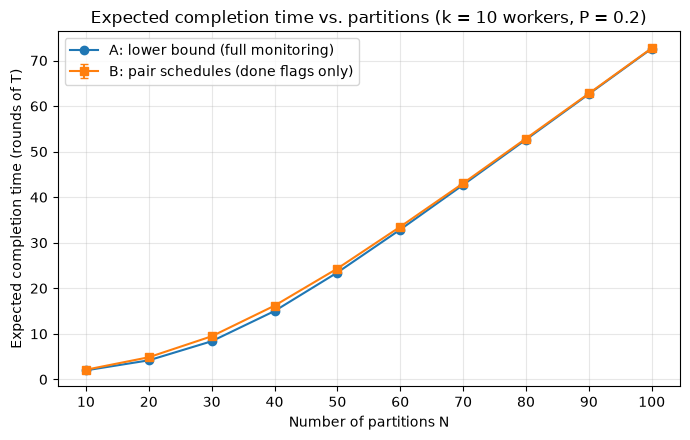

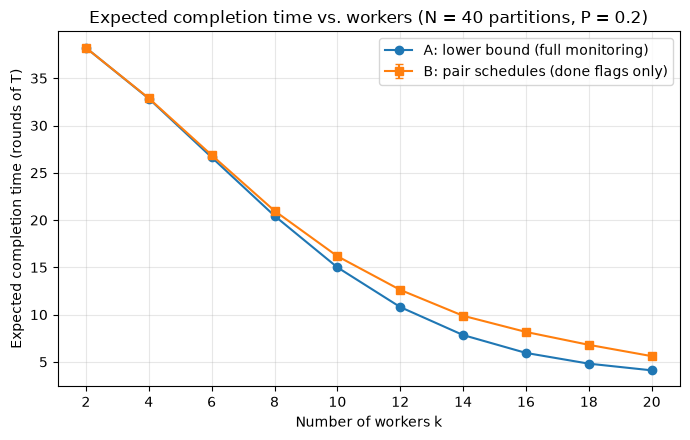

In [10]:

P = 0.2            # failure probability per worker per round
RUNS = 20_000      # simulation runs per point


def A_expected_rounds(N, k, P):
    """Method A (lower bound): exact for up to 10 workers, simulated above that."""
    if k <= 10:
        return A_expected_rounds_recursive(N, k, P)
    return A_expected_rounds_simulated(N, k, P, runs=RUNS)[0]


def B_expected_rounds(N, k, P):
    """Method B (pair schedules): simulated; returns (mean, 95% confidence half-width)."""
    return B_expected_rounds_simulated(pair_schedules(N, k), N, P, runs=RUNS)


def plot_comparison(x_values, A_values, B_means, B_cis, xlabel, title, filename):
    plt.figure(figsize=(7, 4.5))
    plt.plot(x_values, A_values, "o-", label="A: lower bound (full monitoring)")
    plt.errorbar(x_values, B_means, yerr=B_cis, fmt="s-", capsize=3, label="B: pair schedules (done flags only)")
    plt.xticks(x_values)                       # whole-number ticks at the values tested
    plt.xlabel(xlabel)
    plt.ylabel("Expected completion time (rounds of T)")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()


# ---------- Graph 1: increasing partitions, k = 10 workers ----------
k = 10
N_values = list(range(10, 101, 10))

A_values, B_means, B_cis = [], [], []
for N in N_values:
    A_values.append(A_expected_rounds(N, k, P))
    mean, ci = B_expected_rounds(N, k, P)
    B_means.append(mean)
    B_cis.append(ci)

plot_comparison(N_values, A_values, B_means, B_cis,
                xlabel="Number of partitions N",
                title=f"Expected completion time vs. partitions (k = {k} workers, P = {P})",
                filename="graph_increasing_partitions.png")


# ---------- Graph 2: increasing workers, N = 40 partitions ----------
N = 40
k_values = list(range(2, 21, 2))          # pair schedules need an even number of workers

A_values, B_means, B_cis = [], [], []
for k in k_values:
    A_values.append(A_expected_rounds(N, k, P))
    mean, ci = B_expected_rounds(N, k, P)
    B_means.append(mean)
    B_cis.append(ci)

plot_comparison(k_values, A_values, B_means, B_cis,
                xlabel="Number of workers k",
                title=f"Expected completion time vs. workers (N = {N} partitions, P = {P})",
                filename="graph_increasing_workers.png")